# Lab 2: K-Nearest Neighbors and Radius Neighbors Classification

**Name:** Amit Yadav  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50)  
**Assignment:** Lab 2 – KNN and Radius Neighbors Classification Using the Wine Dataset

## Purpose

The purpose of this lab is to evaluate and compare the performance of K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) classifiers using the Wine dataset from scikit-learn. Different values of k and radius are tested to examine how these parameters influence classification accuracy. The results are then visualized and compared to identify effective parameter choices for each classifier.

In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
wine = load_wine()

X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of features:", len(wine.feature_names))
print("Class names:", wine.target_names)

Dataset shape: (178, 13)
Number of features: 13
Class names: ['class_0' 'class_1' 'class_2']


In [3]:
print("Feature Names:")
for feature in wine.feature_names:
    print(feature)

Feature Names:
alcohol
malic_acid
ash
alcalinity_of_ash
magnesium
total_phenols
flavanoids
nonflavanoid_phenols
proanthocyanins
color_intensity
hue
od280/od315_of_diluted_wines
proline


In [4]:
wine_df = pd.DataFrame(X, columns=wine.feature_names)
wine_df["class"] = y

wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
print("Class Distribution:")
print(wine_df["class"].value_counts().sort_index())

Class Distribution:
class
0    59
1    71
2    48
Name: count, dtype: int64


### Dataset Exploration Observation

The Wine dataset contains 178 observations and 13 numerical features representing different chemical properties of wine. The target variable contains three classes. The class distribution is reasonably balanced, although Class 1 contains slightly more observations than Classes 0 and 2.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


## Step 2: K-Nearest Neighbors (KNN)

The KNN classifier was evaluated using k values of 1, 5, 11, 15, and 21. Each model was trained using the training dataset and evaluated on the testing dataset to measure classification accuracy.

In [7]:
k_values = [1, 5, 11, 15, 21]
knn_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    knn_accuracies.append(accuracy)

    print(f"k = {k}: Accuracy = {accuracy:.4f}")

k = 1: Accuracy = 0.7778
k = 5: Accuracy = 0.8056
k = 11: Accuracy = 0.8056
k = 15: Accuracy = 0.8056
k = 21: Accuracy = 0.8056


In [8]:
knn_results = pd.DataFrame({
    "K Value": k_values,
    "Accuracy": knn_accuracies
})

knn_results

,K Value,Accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


## Step 3: Radius Neighbors Classifier (RNN)

The Radius Neighbors classifier was evaluated using radius values of 350, 400, 450, 500, 550, and 600. Each model was trained using the training dataset and evaluated on the testing dataset to measure classification accuracy.

In [9]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_accuracies = []

for radius in radius_values:
    rnn = RadiusNeighborsClassifier(
        radius=radius,
        outlier_label="most_frequent"
    )

    rnn.fit(X_train, y_train)

    y_pred = rnn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    rnn_accuracies.append(accuracy)

    print(f"Radius = {radius}: Accuracy = {accuracy:.4f}")

Radius = 350: Accuracy = 0.7222
Radius = 400: Accuracy = 0.6944
Radius = 450: Accuracy = 0.6944
Radius = 500: Accuracy = 0.6944
Radius = 550: Accuracy = 0.6667
Radius = 600: Accuracy = 0.6667


In [10]:
rnn_results = pd.DataFrame({
    "Radius": radius_values,
    "Accuracy": rnn_accuracies
})

rnn_results

,Radius,Accuracy
0,350,0.722222
1,400,0.694444
2,450,0.694444
3,500,0.694444
4,550,0.666667
5,600,0.666667


## Step 4: Visualize and Compare Results

The following plots show how classification accuracy changes for different values of k in KNN and different radius values in the Radius Neighbors classifier.

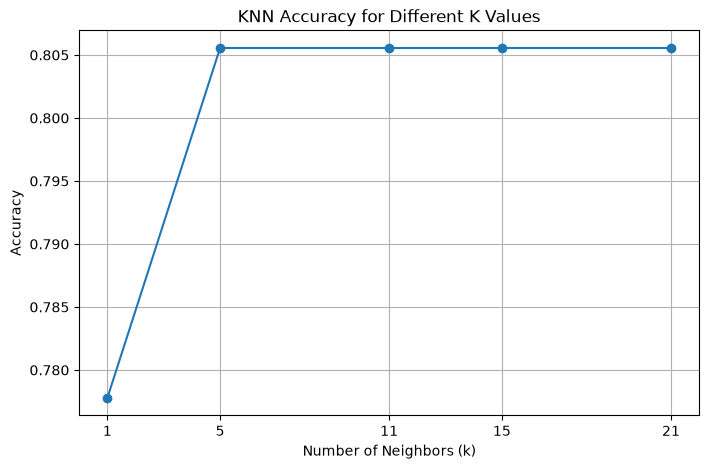

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, knn_accuracies, marker="o")

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(True)

plt.show()

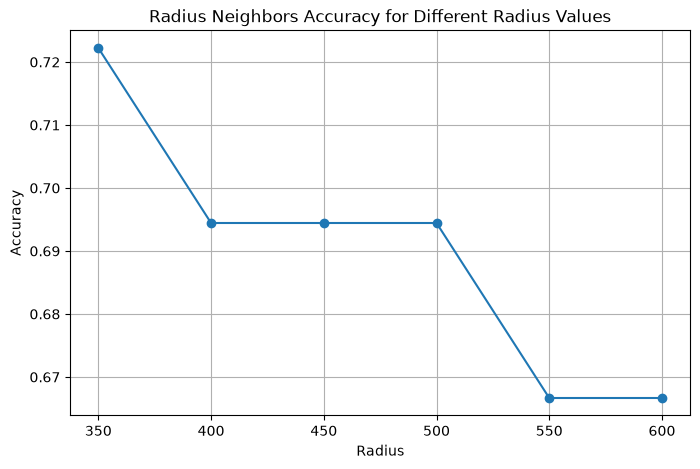

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(radius_values, rnn_accuracies, marker="o")

plt.title("Radius Neighbors Accuracy for Different Radius Values")
plt.xlabel("Radius")
plt.ylabel("Accuracy")
plt.xticks(radius_values)
plt.grid(True)

plt.show()

## Results and Observations

The KNN results show that accuracy improved from 0.7778 at k = 1 to 0.8056 at k = 5. The same accuracy of 0.8056 was maintained for k values of 11, 15, and 21. This indicates that using more than one neighbor improved the model's stability for this dataset, while increasing k beyond 5 did not provide any additional improvement.

The Radius Neighbors classifier produced its highest accuracy of 0.7222 at a radius of 350. Accuracy decreased to 0.6944 for radius values of 400, 450, and 500, and then dropped further to 0.6667 for radius values of 550 and 600. This shows that larger radius values caused the model to include more distant observations, which reduced classification performance.

Overall, KNN performed better than Radius Neighbors for the parameter values tested in this lab. The best KNN accuracy was 0.8056, while the best RNN accuracy was 0.7222.

KNN may be preferable when a fixed number of nearby observations provides reliable local information and when the data distribution is reasonably consistent. Radius Neighbors may be useful when local data density varies because it considers all observations within a specified distance instead of requiring a fixed number of neighbors. However, its performance depends heavily on selecting an appropriate radius.

## Conclusion

This lab demonstrated how parameter selection affects the performance of K-Nearest Neighbors and Radius Neighbors classifiers. For KNN, increasing k from 1 to 5 improved accuracy, while higher values produced the same result. For Radius Neighbors, the smallest tested radius of 350 produced the highest accuracy, while increasing the radius generally reduced performance. Based on the results, KNN was the stronger classifier for the Wine dataset under the tested settings. The experiment shows that selecting appropriate neighborhood parameters is important for achieving good classification performance.